# Experiment 4
## Electricity demand forecasting
### Real data

In [43]:
import sys, os
sys.path.append(os.path.abspath("..")) 
import importlib
import itertools
import src.ridge_signatures
importlib.reload(src.ridge_signatures)
import jax.numpy as jnp
from src.imports import * 
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_real
from src.utils import setup_latex_plotting, exponential_smoothing

### Load data

In [21]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])
dates = df["DateTime"]

In [22]:
total_nb_days = df.size / 48

### Fit RidgeSig on data and calculate error metrics

In [ ]:
from sklearn.metrics import mean_squared_error

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Set parameters and define dictionaries 

delay_days = 7
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
trunc_orders = [4,5,6]
lambdas = [ 0.001] #, 0.01, 0.1, 1, 10, 10**12] #np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
alpha1 = 0.005
#lams_efm = np.array([jnp.array([ 0.2, 0.03]), jnp.array([ 0.2, 0.03])])# np.linspace(16,20,10) #confiugure lambdas for EFMnp.log(2)/windows #
#lambda1_vals = np.logspace(-2, 0, 5)   # 0.01 → 1
#lambda2_vals = np.logspace(-2, 0, 5)
lambda1_vals = np.linspace(0.04, 0.075, 5) #Best rmse around 0.1 for trunc 5 
lambda2_vals = np.linspace(0.000, 0.0001, 5)

lams_efm = np.array([
    jnp.array([l1, l2])
    for l1, l2 in itertools.product(lambda1_vals, lambda2_vals)
])
n_lams = lams_efm.shape[0]


METRICS = {
    "rmse": root_mean_squared_error,
    "mae": mean_absolute_error,
    "mape": mean_absolute_percentage_error,
}

models = {
    rf"$\overline{{T}}, {{\overline{{T}}}}^2": "baseline1",
    rf"$T, T^2, \overline{{T}}, {{\overline{{T}}}}^2$": "baseline2",
    rf"$\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$": "baseline3"
}

errors_sig = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}

metrics = ("rmse",)# "mae", "mape")

best_penalty = {}

# Fit RidgeSig and calculate error metrics 
for j, d in enumerate(trunc_orders):
    for k, lam in enumerate(lams_efm):
        for m in metrics: 
            print(f'processing for {lam}')
            result_efm = ridge_signatures(
                covariates=temp,
                target=consumption / 10000,
                window=0, # not needed for EFM
                delay=delay,
                n_train=n_train,
                n_valid=n_valid,
                trunc_order=d,
                penalties=lambdas,
                tune_penalty=True,
                metric=m,
                signature_type='efm',
                T=total_nb_days,
                lam = lam, # EFM lambda is taken as constant
                max_window=max(windows), # window taken for the convergence of EFM 
                scale = True
            )
            errors_sig[d][m][k] = result_efm["error_test"]
            best_penalty[(d,k,m)] = result_efm['best_penalty']

processing for [0.04 0.  ]
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 6.32 seconds
EFM signatures shape: (68352, 63)
X_train: (33312, 63)
X_val: (17520, 63)
X_test: (17520, 63)
-----------------------------------------
total train+val+test: 68352
total data: 68352
0.5744576294791475 inf 0.001 0.001
processing for [4.0e-02 2.5e-05]
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 6.32 seconds
EFM signatures shape: (68352, 63)
X_train: (33312, 63)
X_val: (17520, 63)
X_test: (17520, 63)
-----------------------------------------
total train+val+test: 68352
total data: 68352
0.4951301736617509 inf 0.001 0.001
processing for [4.e-02 5.e-05]
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 6.19 seconds
EFM signatures shape: (68352, 63)
X_train: (33312, 63)
X_val: (17520, 63)
X_test: (17520, 63)
-----------------------------------------
total train+val+te

In [97]:
min_idx = np.argmin(np.array(errors_sig[5]['rmse'])) 
print(f"Best rmse: {errors_sig[5]['rmse'][min_idx]} for lamda:{lams_efm[min_idx]}")

Best rmse: 0.2713347966152758 for lamda:[0.06625 0.     ]


In [100]:
lambda2_vals

array([0.0e+00, 2.5e-05, 5.0e-05, 7.5e-05, 1.0e-04])

In [98]:
errors = []
for d in trunc_orders:
    row = {"model": f"Ridge regression (depth={d})"}
    row['rmse'] = errors_sig[d]['rmse'].min()
    errors.append(row)
print(errors)

[{'model': 'Ridge regression (depth=5)', 'rmse': 0.2713347966152758}]


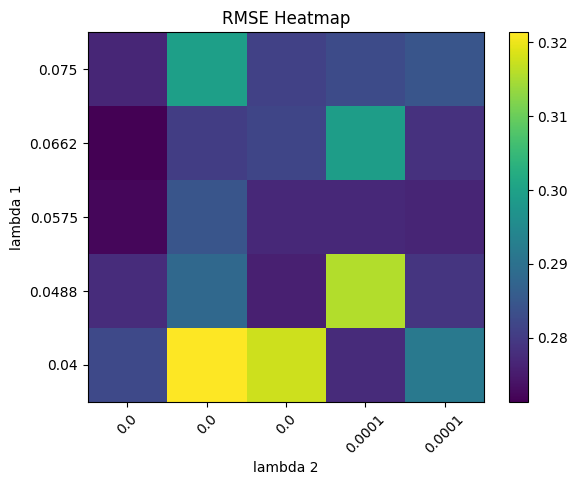

In [99]:
import numpy as np
import matplotlib.pyplot as plt

errors_flat = np.array(errors_sig[5]['rmse'])
errors_grid = errors_flat.reshape(len(lambda1_vals), len(lambda2_vals))

# Create heatmap
plt.figure()
plt.imshow(errors_grid, origin='lower', aspect='auto')

plt.xticks(range(len(lambda2_vals)), np.round(lambda2_vals, 4), rotation=45)
plt.yticks(range(len(lambda1_vals)), np.round(lambda1_vals, 4))

plt.xlabel("lambda 2")
plt.ylabel("lambda 1")
plt.title("RMSE Heatmap")

plt.colorbar()
plt.show()


### Fit baseline models and compare

In [ ]:
errors = []
windows_days = np.array(range(delay_days, n_windows + delay_days))
base_results = run_baselines_real(temp, consumption, n_train+n_valid, alpha1, delay_days)

# Baseline models
for label, key in models.items():
    row = {"model": label}
    for m_name in METRICS.keys():
        row[m_name] = base_results[key]["metrics_test"][m_name]
    errors.append(row)

# Naive lag model (Y_{t-7 days})
row = {"model": r"$Y_{t-\text{7 days}}$"}
for m_name, m_func in METRICS.items():
    row[m_name] = m_func(
        consumption[n_train:],
        consumption[n_train - delay_days * 48 : -delay_days * 48]
    )
errors.append(row)

# Ridge regression on signatures (minimum across windows, per metric and depth)
for d in trunc_orders:
    row = {"model": f"Ridge regression (depth={d})"}
    for m_name in METRICS.keys():
        row[m_name] = errors_sig[d][m_name].min()
    errors.append(row)

results_df = pd.DataFrame(errors)
print(tabulate(results_df, headers='keys', tablefmt='grid', showindex=False))


### Compare predictions from best RidgeSig and baseline model

In [ ]:
# Parameters
delay_days = 7
delay = delay_days*48
window_days = 9
window = window_days*48
trunc_order = 7
lambdas = [0.001] #np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
metric = "rmse"
lam = 0.5
# Obtain predictions for the best performing RidgeSig model (best window size)
result = ridge_signatures(
    covariates=temp,
    target=consumption,
    window=0, # not needed for EFM
    delay=delay,
    n_train=n_train,
    n_valid=n_valid,
    trunc_order=trunc_order,
    penalties=lambdas,
    tune_penalty=True,
    metric=metric,
    signature_type='efm',
    T=total_nb_days,
    lam = np.array([lam]), # EFM lambda is taken as constant
    max_window=max(windows) # window taken for the convergence of EFM 
)
y_pred_sig = result["y_pred_test"]


# Refit the best baseline so dates are aligned
alpha1 = 0.005
temp_smooth1 = exponential_smoothing(temp, smooth_param=alpha1)
datetime = df["DateTime"]

df_reg = pd.DataFrame({
    "Temperature": temp,
    "Temp_sq": temp**2,
    "Temp_smooth1": temp_smooth1,
    "Temp_smooth1_sq": temp_smooth1**2,
    "Consumption": consumption
})

df_reg["Consumption_delay"] = df_reg["Consumption"].shift(delay)
df_model = df_reg.dropna().reset_index(drop=True)
X = df_model[["Temperature", "Temp_sq", "Temp_smooth1", "Temp_smooth1_sq", "Consumption_delay"]]
y = df_model["Consumption"]

X_train, X_test = X.iloc[window:n_train+n_valid+window], X.iloc[n_train+n_valid+window:]
y_train, y_test = y.iloc[window:n_train+n_valid+window], y.iloc[n_train+n_valid+window:]

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_baseline = lr.predict(X_test)

# Align dates
dates_train_valid = dates[window:n_train + n_valid + window]
dates_test  = dates[n_train + n_valid + window:]
consumption_train = consumption[window:n_train + n_valid + window]
consumption_test  = consumption[n_train + n_valid + window:]

# Plot
setup_latex_plotting()
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# First plot - winter week
start_winter = "2015-02-02 00:00:00"
end_winter  = "2015-02-17 23:30:00"

mask = (dates_test >= start_winter) & (dates_test <= end_winter)
mask_indices = np.where(mask)[0]
mask_indices1 = np.where(mask)[0]+max(windows)
n_points = len(consumption_test[mask_indices])
day_ticks = np.arange(0, n_points+1, 48)
day_labels = np.arange(0, len(day_ticks))  # 0, 1, 2, ...

axes[0].plot(consumption_test[mask_indices], label="Real", color="#333333")
axes[0].plot(y_pred_sig[mask_indices1], label=f"RidgeSig, lam={lam}",color="#7AD151")
axes[0].plot(
    y_pred_baseline[mask_indices],
    label=rf"$RL\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$",
    color="#1f77b4"
)
axes[0].set_ylabel("Demand",fontsize=10)
axes[0].set_title(f"From {start_winter} to {end_winter}", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(labelbottom=False)  


#  Second plot - summer week

start_summer = "2015-06-15 00:00:00"
end_summer   = "2015-06-30 23:30:00"
mask_summer = (dates_test >= start_summer) & (dates_test <= end_summer)
mask_summer_indices = np.where(mask_summer)[0]
mask_summer_indices1 = np.where(mask_summer)[0]+max(windows)
axes[1].plot(consumption_test[mask_summer_indices], label="Real",color="#333333")
axes[1].plot(y_pred_sig[mask_summer_indices1], label=f"RidgeSig, window={window_days} days",color="#7AD151")
axes[1].plot(
    y_pred_baseline[mask_summer_indices],
    label=rf"$RL\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$",
    color="#1f77b4"
)
axes[1].set_ylabel("Demand",fontsize=10)
axes[1].set_title(f"From {start_summer} to {end_summer}", fontsize=10)
axes[1].set_xlabel("Days",fontsize=10)
axes[1].set_xticks(day_ticks)
axes[1].set_xticklabels(day_labels)
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


Use this one:

In [101]:
# Parameters
delay_days = 7
delay = delay_days*48
window_days = 9
window = window_days*48
trunc_order = 8
lambdas = [0.001,0.1, 1,10] #np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
metric = "rmse"
lam = np.array([jnp.array([0.06625 ,0 ])])
# Obtain predictions for the best performing RidgeSig model (best window size)
result = ridge_signatures(
    covariates=temp,
    target=consumption,
    window=0, # not needed for EFM
    delay=delay,
    n_train=n_train,
    n_valid=n_valid,
    trunc_order=trunc_order,
    penalties=lambdas,
    tune_penalty=True,
    metric=metric,
    signature_type='efm',
    T=total_nb_days,
    lam = lam[0], #
    max_window=max(windows) # window taken for the convergence of EFM 
)
y_pred_sig = result["y_pred_test"]

t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 398.77 seconds
EFM signatures shape: (68352, 511)
X_train: (33312, 511)
X_val: (17520, 511)
X_test: (17520, 511)
-----------------------------------------
total train+val+test: 68352
total data: 68352
22958.952025904833 inf 0.001 0.001
22958.95202647717 22958.952025904833 0.1 0.001
22958.952025116934 22958.952025904833 1 0.001
22958.952025691047 22958.952025116934 10 1


findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

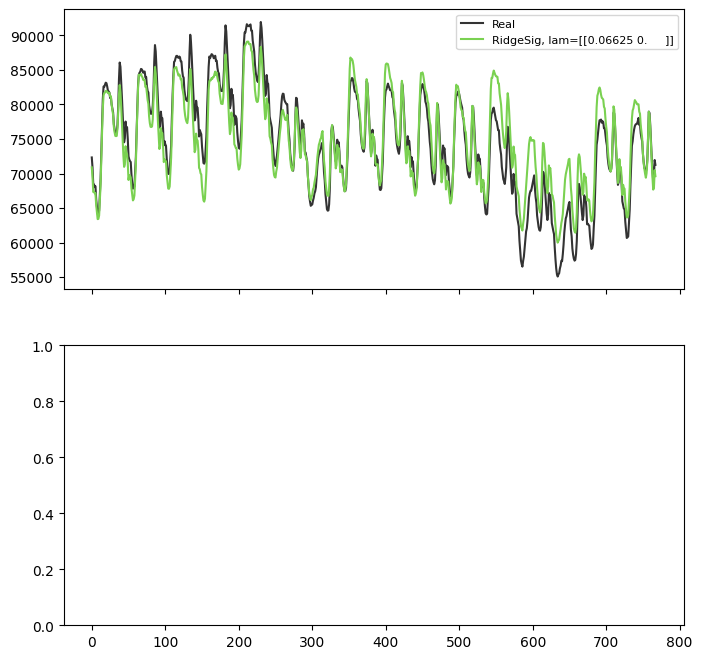

In [102]:

datetime = df["DateTime"]


window = 0 #window_days*48
# Align dates
dates_train_valid = dates[window:n_train + n_valid + window]
dates_test  = dates[n_train + n_valid + window:]
consumption_train = consumption[window:n_train + n_valid + window]
consumption_test  = consumption[n_train + n_valid + window:]

# Plot
setup_latex_plotting()
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# First plot - winter week
start_winter = "2015-02-02 00:00:00"
end_winter  = "2015-02-17 23:30:00"

mask = (dates_test >= start_winter) & (dates_test <= end_winter)
mask_indices = np.where(mask)[0]
mask_indices1 = np.where(mask)[0]
n_points = len(consumption_test[mask_indices])
day_ticks = np.arange(0, n_points+1, 48)
day_labels = np.arange(0, len(day_ticks))  

axes[0].plot(consumption_test[mask_indices], label="Real", color="#333333")
axes[0].plot(y_pred_sig[mask_indices1], label=f"RidgeSig, lam={lam}",color="#7AD151")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(labelbottom=False)  
plt.show()


findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

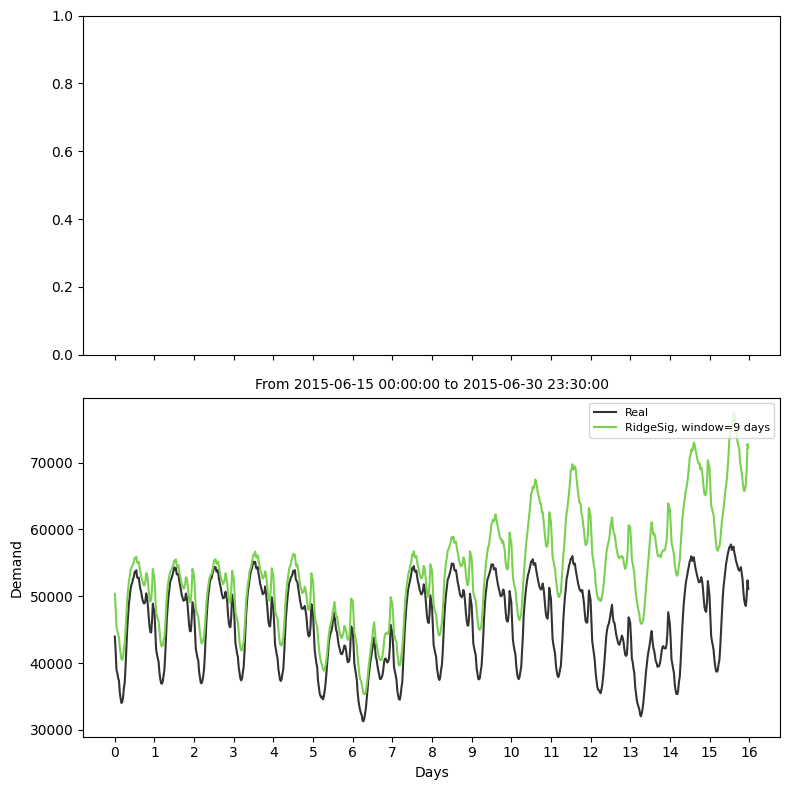

In [103]:

#  Second plot - summer week
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
start_summer = "2015-06-15 00:00:00"
end_summer   = "2015-06-30 23:30:00"
mask_summer = (dates_test >= start_summer) & (dates_test <= end_summer)
mask_summer_indices = np.where(mask_summer)[0]
mask_summer_indices1 = np.where(mask_summer)[0]

axes[1].plot(consumption_test[mask_summer_indices], label="Real",color="#333333")
axes[1].plot(y_pred_sig[mask_summer_indices1], label=f"RidgeSig, window={window_days} days",color="#7AD151")
axes[1].set_ylabel("Demand",fontsize=10)
axes[1].set_title(f"From {start_summer} to {end_summer}", fontsize=10)
axes[1].set_xlabel("Days",fontsize=10)
axes[1].set_xticks(day_ticks)
axes[1].set_xticklabels(day_labels)
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()
